In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union





Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA749643/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,aliquot,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,⋯,LibraryLayout,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR15244138,San82,AMPLICON,598,68896097,PRJNA749643,SAMN20395361,Metagenome or environmental,41880635,SPANISH RESEARCH COUNCIL,⋯,PAIRED,PCR,METAGENOMIC,metagenome,ILLUMINA,2022-09-20T00:00:00Z,2021-07-26T22:42:00Z,1,San82,SRP329834
2,SRR15244139,San77,AMPLICON,598,50369697,PRJNA749643,SAMN20395360,Metagenome or environmental,30762536,SPANISH RESEARCH COUNCIL,⋯,PAIRED,PCR,METAGENOMIC,metagenome,ILLUMINA,2022-09-20T00:00:00Z,2021-07-26T22:42:00Z,1,San77,SRP329834
3,SRR15244140,San75,AMPLICON,596,16656189,PRJNA749643,SAMN20395359,Metagenome or environmental,10326642,SPANISH RESEARCH COUNCIL,⋯,PAIRED,PCR,METAGENOMIC,metagenome,ILLUMINA,2022-09-20T00:00:00Z,2021-07-26T22:42:00Z,1,San75,SRP329834
4,SRR15244141,San73,AMPLICON,598,51734538,PRJNA749643,SAMN20395358,Metagenome or environmental,31938992,SPANISH RESEARCH COUNCIL,⋯,PAIRED,PCR,METAGENOMIC,metagenome,ILLUMINA,2022-09-20T00:00:00Z,2021-07-26T22:42:00Z,1,San73,SRP329834
5,SRR15244142,San69,AMPLICON,598,60540954,PRJNA749643,SAMN20395357,Metagenome or environmental,37093708,SPANISH RESEARCH COUNCIL,⋯,PAIRED,PCR,METAGENOMIC,metagenome,ILLUMINA,2022-09-20T00:00:00Z,2021-07-26T22:44:00Z,1,San69,SRP329834
6,SRR15244143,San67,AMPLICON,598,70628485,PRJNA749643,SAMN20395356,Metagenome or environmental,43454378,SPANISH RESEARCH COUNCIL,⋯,PAIRED,PCR,METAGENOMIC,metagenome,ILLUMINA,2022-09-20T00:00:00Z,2021-07-26T22:42:00Z,1,San67,SRP329834


[1] "Run"                            "aliquot"                       
 [3] "Assay.Type"                     "AvgSpotLen"                    
 [5] "Bases"                          "BioProject"                    
 [7] "BioSample"                      "BioSampleModel"                
 [9] "Bytes"                          "Center.Name"                   
[11] "Collection_Date"                "Consent"                       
[13] "DATASTORE.filetype"             "DATASTORE.provider"            
[15] "DATASTORE.region"               "Experiment"                    
[17] "geo_loc_name_country"           "geo_loc_name_country_continent"
[19] "geo_loc_name"                   "Instrument"                    
[21] "isolation_source"               "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Organism"                       "Platform"                      
[29] "ReleaseDate"                    "create_date"                   
[31] "version"                        "Sample.Name"                   
[33] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC',
    title = "Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 21
[1] 21


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA749643,SRR15244138,San82,NA,NA,NA,V3-V4,ILLUMINA,Spain,saliva,2022-09-20T00:00:00Z,F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC,Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis,YES,NA,NO
2,PRJNA749643,SRR15244139,San77,NA,NA,NA,V3-V4,ILLUMINA,Spain,saliva,2022-09-20T00:00:00Z,F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC,Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis,YES,NA,NO
3,PRJNA749643,SRR15244140,San75,NA,NA,NA,V3-V4,ILLUMINA,Spain,saliva,2022-09-20T00:00:00Z,F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC,Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis,YES,NA,NO
4,PRJNA749643,SRR15244141,San73,NA,NA,NA,V3-V4,ILLUMINA,Spain,saliva,2022-09-20T00:00:00Z,F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC,Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis,YES,NA,NO
5,PRJNA749643,SRR15244142,San69,NA,NA,NA,V3-V4,ILLUMINA,Spain,saliva,2022-09-20T00:00:00Z,F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC,Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis,YES,NA,NO
6,PRJNA749643,SRR15244143,San67,NA,NA,NA,V3-V4,ILLUMINA,Spain,saliva,2022-09-20T00:00:00Z,F: CCTACGGGNBGCASCAG; R: GACTACNVGGGTATCTAATCC,Ulcerative Colitis Seems to Imply Oral Microbiome Dysbiosis,YES,NA,NO


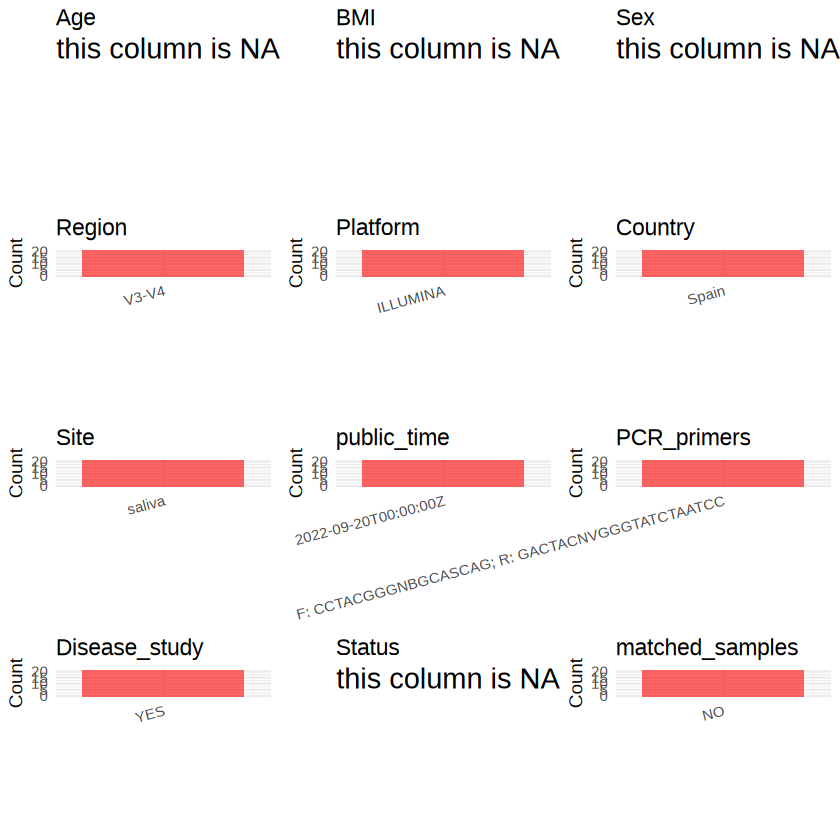

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA749643/metadata.csv", quote = T)